In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_excel('Supermarket Sales Analysis dashboard.xlsx', sheet_name='BlinkIT Grocery Data')
df.head(10)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0
5,low fat,FDS52,Frozen Foods,2020,OUT017,Tier 2,Small,Supermarket Type1,0.005505,8.89,102.4016,5.0
6,Low Fat,NCU05,Health and Hygiene,2011,OUT010,Tier 3,Small,Grocery Store,0.098312,11.80,81.4618,5.0
7,Low Fat,NCD30,Household,2015,OUT045,Tier 2,Small,Supermarket Type1,0.026904,19.70,96.0726,5.0
8,Low Fat,FDW20,Fruits and Vegetables,2014,OUT013,Tier 3,High,Supermarket Type1,0.024129,20.75,124.1730,5.0
9,Low Fat,FDX25,Canned,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.101562,NaN,181.9292,5.0


In [3]:
df.info()
df['Item Fat Content'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

In [4]:
df['Item Fat Content'] = df['Item Fat Content'].replace({'low fat': 'Low Fat', 'LF': 'Low Fat', 'reg': 'Regular'})
df['Item Fat Content'].value_counts()

Item Fat Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64

In [5]:
total_sales = df['Sales'].sum()
avg_sales = df['Sales'].mean()
avg_visibility = df['Item Visibility'].mean()

print(round(total_sales, 2))
print(round(avg_sales, 2))
print(round(avg_visibility, 4))


1201681.49
140.99
0.0661


In [6]:
category_sales = df.groupby('Item Type')['Sales'].sum().sort_values(ascending=False)

top4_sum = category_sales.head(4).sum()
remaining_sum = category_sales.head(4).sum()

print((top4_sum / total_sales) * 100)
print((remaining_sum / total_sales) * 100)
print(category_sales.index[0], category_sales.iloc[0])
print(category_sales.index[-1], category_sales.iloc[-1])

outlet_summary = df.groupby('Outlet Type')['Sales'].agg(['sum', 'count', 'mean'])
outlet_summary['pct_total'] = (outlet_summary['sum'] / total_sales) * 100   
outlet_summary


50.60354293907788
50.60354293907788
Fruits and Vegetables 178124.081
Seafood 9077.87


,sum,count,mean,pct_total
Outlet Type,,,,
Grocery Store,151939.1490,1083,140.294690,12.643879
Supermarket Type1,787549.8928,5577,141.213895,65.537324
Supermarket Type2,131477.7764,928,141.678638,10.941150
Supermarket Type3,130714.6746,935,139.801791,10.877647


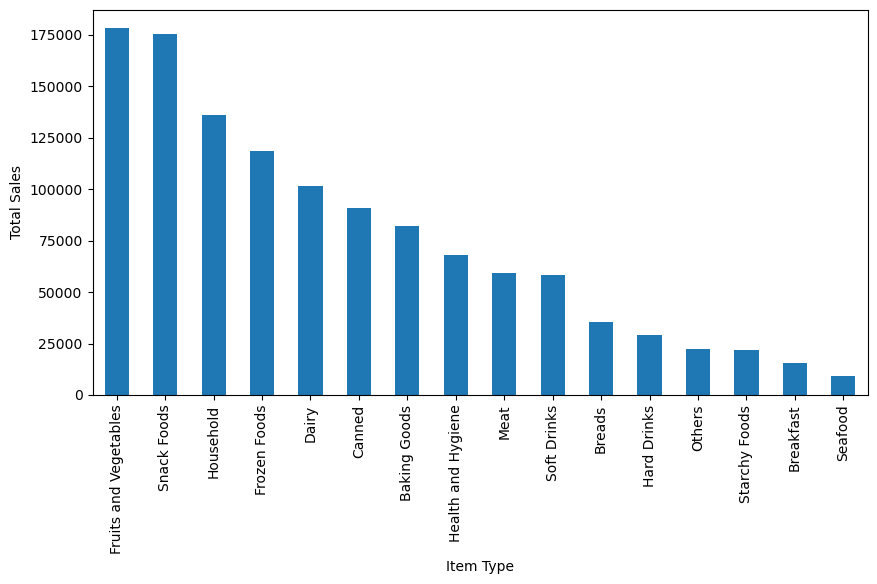

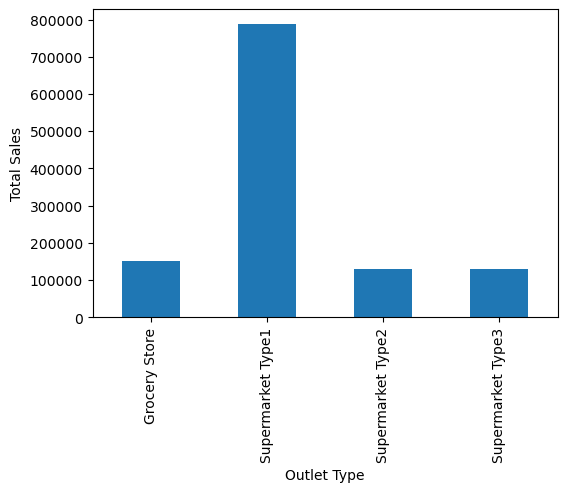

In [7]:
plt.figure(figsize=(10, 5))
category_sales.plot(kind='bar')
plt.ylabel('Total Sales')
plt.show()

plt.figure(figsize=(6, 4))
df.groupby('Outlet Type')['Sales'].sum().plot(kind='bar')
plt.ylabel('Total Sales')
plt.show()

-0.0013


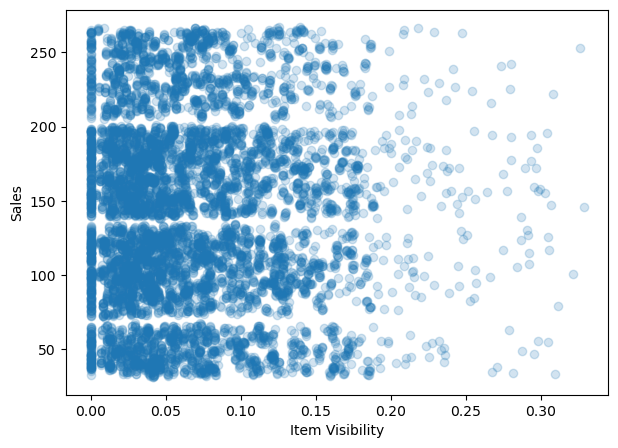

In [8]:
fat_by_outlet = df.pivot_table(index='Outlet Type', columns='Item Fat Content', values='Sales', aggfunc='sum')
fat_by_outlet

correlation = df['Item Visibility'].corr(df['Sales'])
print(round(correlation, 4))

plt.figure(figsize=(7, 5))
plt.scatter(df['Item Visibility'], df['Sales'], alpha=0.2)
plt.xlabel('Item Visibility')
plt.ylabel('Sales')
plt.show()

In [9]:
stats = df['Sales'].describe()
median_val = df['Sales'].median()
variance_val = df['Sales'].var()

q1 = df['Sales'].quantile(0.25)
q3 = df['Sales'].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

outliers = df[(df['Sales'] < lower_fence) | (df['Sales'] > upper_fence)]

print(stats)
print(round(median_val, 2))
print(round(variance_val, 2))
print(round(iqr, 2))
print(len(outliers))

count    8523.000000
mean      140.992783
std        62.275067
min        31.290000
25%        93.826500
50%       143.012800
75%       185.643700
max       266.888400
Name: Sales, dtype: float64
143.01
3878.18
91.82
0


In [11]:
print(df.groupby('Outlet Location Type')['Sales'].mean())
print(df.groupby('Outlet Type')['Sales'].mean())
print(df.groupby('Item Type')['Sales'].mean())

df.to_csv('cleaned_supermarket_sales.csv', index=False)

Outlet Location Type
Tier 1    140.870106
Tier 2    141.167198
Tier 3    140.935234
Name: Sales, dtype: float64
Outlet Type
Grocery Store        140.294690
Supermarket Type1    141.213895
Supermarket Type2    141.678638
Supermarket Type3    139.801791
Name: Sales, dtype: float64
Item Type
Baking Goods             126.380766
Breads                   140.952669
Breakfast                141.788151
Canned                   139.763835
Dairy                    148.499211
Frozen Foods             138.503366
Fruits and Vegetables    144.581235
Hard Drinks              137.077947
Health and Hygiene       130.818921
Household                149.424753
Meat                     139.882032
Others                   132.851430
Seafood                  141.841719
Snack Foods              146.194935
Soft Drinks              131.492510
Starchy Foods            147.838023
Name: Sales, dtype: float64
